# 02 · Main analysis

I compare each campaign against control, and the two campaigns against each other, on the three metrics defined in the plan:

| Comparison | Question |
|---|---|
| H1: Mens vs Control | Does the men's email drive results? |
| H2: Womens vs Control | Does the women's email drive results? |
| H3: Mens vs Womens | Which of the two is better? |

The three comparisons for each metric are adjusted with Holm. The analysis is intention-to-treat: every customer is compared according to the group they were assigned to.

In [1]:
import sys
sys.path.append("..")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from src.dataset import load, GROUP_ORDER, COLORS, FIGURES
from src.stats_utils import compare_proportions, compare_means, bootstrap_difference, results_table

plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False})

df = load()
COMPARISONS = [("Mens", "Control"), ("Womens", "Control"), ("Mens", "Womens")]

## 1. Results by group

In [2]:
by_group = df.groupby("group", observed=True).agg(
    customers=("spend", "size"),
    visit_rate=("visit", "mean"),
    conversion_rate=("conversion", "mean"),
    revenue_per_customer=("spend", "mean"),
    total_revenue=("spend", "sum"),
)
by_group.style.format({
    "customers": "{:,.0f}", "visit_rate": "{:.2%}", "conversion_rate": "{:.2%}",
    "revenue_per_customer": "${:.3f}", "total_revenue": "${:,.0f}",
})

,customers,visit_rate,conversion_rate,revenue_per_customer,total_revenue
group,,,,,
Control,"21,306",10.62%,0.57%,$0.653,"$13,908"
Mens,"21,307",18.28%,1.25%,$1.423,"$30,312"
Womens,"21,387",15.14%,0.88%,$1.077,"$23,038"


## 2. Hypothesis tests

- Visits and conversion: difference in proportions, 95% Wald CI and z-test.
- Revenue per customer: difference in means with Welch's test (it does not assume equal variances; the Mens group has a standard deviation 50% larger than control).

In [3]:
results = []
for metric, test in [("visit", compare_proportions), ("conversion", compare_proportions), ("spend", compare_means)]:
    for a, b in COMPARISONS:
        results.append(test(df.loc[df.group == a, metric], df.loc[df.group == b, metric], metric, f"{a} vs {b}"))

table = results_table(results)
table["significant"] = np.where(table.p_holm < 0.05, "Yes", "No")


def fmt(t):
    t = t.copy()
    is_prop = t.metric != "spend"
    for col in ["treatment", "control", "difference", "ci_low", "ci_high"]:
        t[col] = np.where(is_prop, t[col].map(lambda v: f"{v:.2%}"), t[col].map(lambda v: f"${v:.3f}"))
    t["lift"] = t["lift"].map(lambda v: f"{v:+.0%}")
    t["p_value"] = t["p_value"].map(lambda v: f"{v:.2g}")
    t["p_holm"] = t["p_holm"].map(lambda v: f"{v:.2g}")
    return t.set_index(["metric", "comparison"])


fmt(table)

treatment control  ...    p_holm significant
metric     comparison                           ...                      
visit      Mens vs Control      18.28%  10.62%  ...  1.7e-111         Yes
           Womens vs Control    15.14%  10.62%  ...   6.4e-44         Yes
           Mens vs Womens       18.28%  15.14%  ...   3.8e-18         Yes
conversion Mens vs Control       1.25%   0.57%  ...   4.6e-13         Yes
           Womens vs Control     0.88%   0.57%  ...   0.00031         Yes
           Mens vs Womens        1.25%   0.88%  ...   0.00031         Yes
spend      Mens vs Control      $1.423  $0.653  ...   3.5e-07         Yes
           Womens vs Control    $1.077  $0.653  ...    0.0023         Yes
           Mens vs Womens       $1.423  $1.077  ...      0.03         Yes

[9 rows x 9 columns]

All nine comparisons are significant after the Holm adjustment. For revenue per customer:

- Mens vs Control: +0.77 USD per customer (95% CI: 0.49 to 1.05), more than double the control.
- Womens vs Control: +0.42 USD per customer (95% CI: 0.17 to 0.68).
- Mens vs Womens: the men's email brings in 0.35 USD more per customer (95% CI: 0.03 to 0.66), with an adjusted p = 0.03. It is the weakest of the three differences: the interval almost touches zero.

The men's email wins on all three metrics.

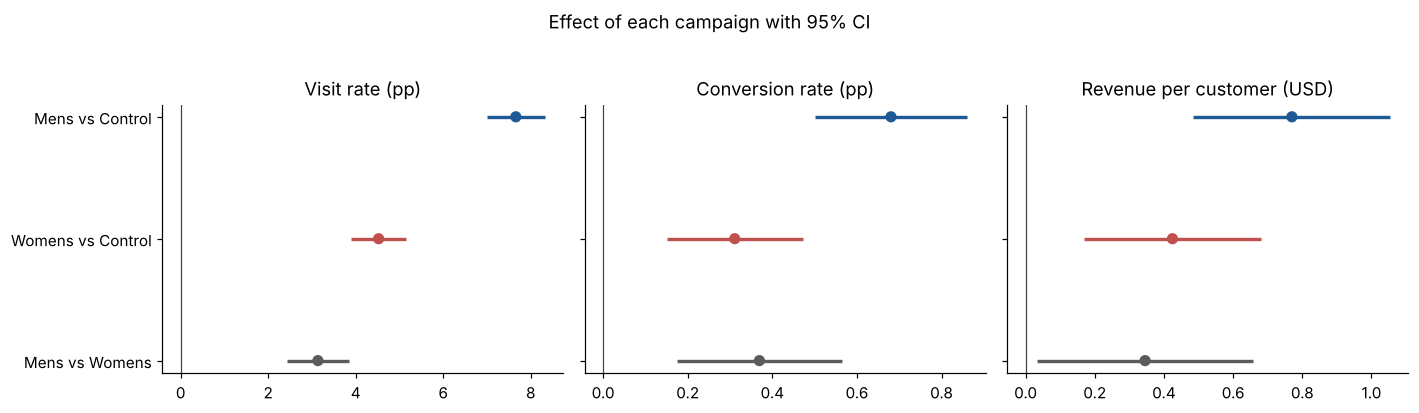

In [4]:
fig, axes = plt.subplots(1, 3, figsize=(13, 3.6))
titles = {"visit": "Visit rate (pp)", "conversion": "Conversion rate (pp)", "spend": "Revenue per customer (USD)"}
for ax, (metric, title) in zip(axes, titles.items()):
    sub = table[table.metric == metric].iloc[::-1]
    scale = 100 if metric != "spend" else 1
    y = np.arange(len(sub))
    colors = [COLORS["Mens"] if c.startswith("Mens vs C") else COLORS["Womens"] if c.startswith("Womens") else "#5B5B5B"
              for c in sub.comparison]
    ax.errorbar(sub.difference * scale, y,
                xerr=[(sub.difference - sub.ci_low) * scale, (sub.ci_high - sub.difference) * scale],
                fmt="none", ecolor=colors, elinewidth=2.2, capsize=0)
    ax.scatter(sub.difference * scale, y, color=colors, zorder=3, s=40)
    ax.axvline(0, color="#444", lw=0.8)
    ax.set_yticks(y, sub.comparison if ax is axes[0] else [""] * len(sub))
    ax.set_title(title)
    ax.set_xlim(left=min(0, (sub.ci_low * scale).min()) - 0.05 * (sub.ci_high * scale).max())
fig.suptitle("Effect of each campaign with 95% CI", y=1.03, fontsize=12)
fig.tight_layout()
fig.savefig(FIGURES / "02_main_effects.png", dpi=150, bbox_inches="tight")

## 3. Bootstrap check

Revenue is more than 99% zeros with a long tail. To confirm that the Welch interval does not depend on the normal approximation, I repeat the calculation with 10,000 bootstrap resamples within each group.

In [5]:
rows = []
distributions = {}
for a, b in COMPARISONS:
    dist = bootstrap_difference(df.loc[df.group == a, "spend"], df.loc[df.group == b, "spend"], n_boot=10_000, seed=42)
    distributions[f"{a} vs {b}"] = dist
    welch = table[(table.metric == "spend") & (table.comparison == f"{a} vs {b}")].iloc[0]
    rows.append({
        "comparison": f"{a} vs {b}",
        "difference": welch.difference,
        "ci_welch": f"[{welch.ci_low:.3f}, {welch.ci_high:.3f}]",
        "ci_bootstrap": f"[{np.percentile(dist, 2.5):.3f}, {np.percentile(dist, 97.5):.3f}]",
        "pct_replicates_<=_0": (dist <= 0).mean(),
    })
pd.DataFrame(rows).set_index("comparison")

,difference,ci_welch,ci_bootstrap,pct_replicates_<=_0
comparison,,,,
Mens vs Control,0.7698,"[0.485, 1.055]","[0.482, 1.052]",0.0000
Womens vs Control,0.4244,"[0.169, 0.680]","[0.172, 0.680]",0.0011
Mens vs Womens,0.3454,"[0.033, 0.658]","[0.036, 0.665]",0.0148


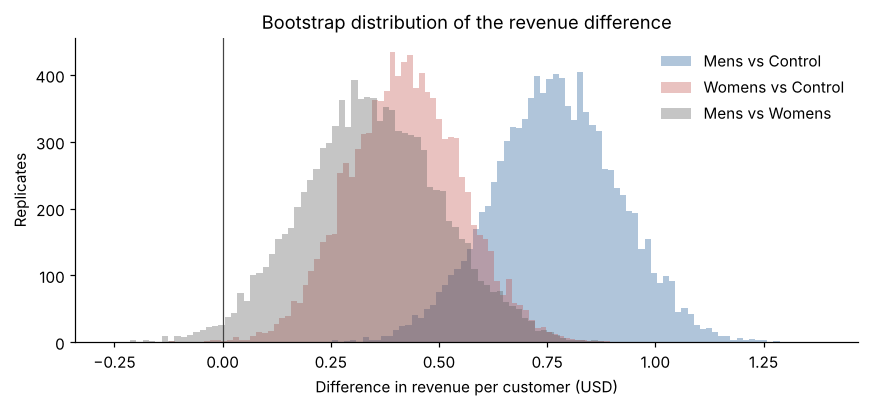

In [6]:
fig, ax = plt.subplots(figsize=(8, 3.8))
palette = {"Mens vs Control": COLORS["Mens"], "Womens vs Control": COLORS["Womens"], "Mens vs Womens": "#5B5B5B"}
for name, dist in distributions.items():
    ax.hist(dist, bins=80, histtype="stepfilled", alpha=0.35, color=palette[name], label=name)
ax.axvline(0, color="#444", lw=0.8)
ax.set_xlabel("Difference in revenue per customer (USD)")
ax.set_ylabel("Replicates")
ax.set_title("Bootstrap distribution of the revenue difference")
ax.legend(frameon=False)
fig.tight_layout()
fig.savefig(FIGURES / "02_bootstrap_revenue.png", dpi=150, bbox_inches="tight")

The bootstrap intervals differ from the Welch intervals by less than 0.01 USD at each end. With ~21k customers per group, the normal approximation works well despite the shape of spend.

## 4. Sensitivity to extreme values

The plan proposed repeating the analysis with spend capped at the 99th percentile, but among buyers the 99th percentile is already the maximum (499 USD), so it would change nothing. Instead I cap at the 95th percentile of buyers. I record this change from the plan here.

In [7]:
buyers = df[df.conversion == 1]
cap = buyers.spend.quantile(0.95)
spend_capped = df.spend.clip(upper=cap)
print(f"Cap (p95 of buyers): {cap:.2f} USD; customers affected: {(df.spend > cap).sum()}")

sensitivity = []
for a, b in COMPARISONS:
    r = compare_means(spend_capped[df.group == a], spend_capped[df.group == b], "spend_capped", f"{a} vs {b}")
    original = table[(table.metric == "spend") & (table.comparison == f"{a} vs {b}")].iloc[0]
    sensitivity.append({
        "comparison": f"{a} vs {b}",
        "diff_original": original.difference,
        "diff_capped": r.difference,
        "ci_capped": f"[{r.ci_low:.3f}, {r.ci_high:.3f}]",
        "p_value_capped": r.p_value,
    })
pd.DataFrame(sensitivity).set_index("comparison").round(4)

Cap (p95 of buyers): 362.20 USD; customers affected: 28


,diff_original,diff_capped,ci_capped,p_value_capped
comparison,,,,
Mens vs Control,0.7698,0.7374,"[0.474, 1.000]",0.0000
Womens vs Control,0.4244,0.4135,"[0.176, 0.651]",0.0007
Mens vs Womens,0.3454,0.3240,"[0.034, 0.614]",0.0287


The conclusions do not depend on a handful of large purchases: the effects shrink slightly and all remain significant.

## 5. Where does the extra revenue come from?

Revenue per customer equals conversion rate × average order value. Order value is only computed among buyers, a group defined after the send, so this decomposition is descriptive, not causal.

In [8]:
decomp = df.groupby("group", observed=True).agg(
    conversion_rate=("conversion", "mean"),
    buyers=("conversion", "sum"),
    revenue_per_customer=("spend", "mean"),
)
decomp["avg_order_value"] = buyers.groupby("group", observed=True)["spend"].mean()
decomp.style.format({"conversion_rate": "{:.2%}", "buyers": "{:,.0f}",
                     "revenue_per_customer": "${:.3f}", "avg_order_value": "${:.2f}"})

,conversion_rate,buyers,revenue_per_customer,avg_order_value
group,,,,
Control,0.57%,122,$0.653,$114.00
Mens,1.25%,267,$1.423,$113.53
Womens,0.88%,189,$1.077,$121.89


Average order value is similar across the three groups (114 to 122 USD). Almost all of the effect comes from more customers buying, not from customers spending more per purchase.

## Conclusion

- Both campaigns increase visits, conversions and revenue compared with sending no email.
- The men's email is the best: +0.77 USD per customer versus control, against +0.42 for the women's email. The difference between them (+0.35 USD) is significant after the Holm adjustment (p = 0.03).
- The result holds up with the bootstrap and when extreme values are capped.
- The effect comes from more buyers, not from larger purchases.

The remaining question is whether to send the same email to everyone or whether some customers respond better to each campaign. That is analyzed in [`03_segments_and_impact.ipynb`](03_segments_and_impact.ipynb).